# Transformations with dbt (Data Build Tool)

**dbt** turns SQL `SELECT` statements into a managed transformation project: each model is a `.sql` file, dependencies come from `ref()`, tests are declared in YAML, documentation and lineage are generated, and everything lives in Git. dbt runs the SQL **inside** the warehouse (ELT). This lesson builds and runs a real dbt project on DuckDB.

**After this lesson you can:**

1. Structure a dbt project: sources, seeds, staging and mart models.
2. Use `ref()` and `source()` so dbt builds the dependency graph.
3. Add generic and singular tests, and run `dbt build`.
4. Build an incremental model, generate documentation, and read the run results.

**Data:** NYC taxi trips (January–February 2024) as a dbt source, the zone lookup as a seed. **Tool:** `dbt-core` with the `dbt-duckdb` adapter (free, open source).

In [1]:
import sys
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
WORK = Path(tempfile.mkdtemp())                   # all warehouses and projects of this lesson live here

import json
import shutil

import os

os.environ["DBT_USE_COLORS"] = "false"           # plain log text (no colour codes) in the notebook
from dbt.cli.main import dbtRunner

PROJ = WORK / "taxi_dbt"
for sub in ["models/staging", "models/marts", "seeds", "tests", "macros"]:
    (PROJ / sub).mkdir(parents=True, exist_ok=True)
shutil.copy(datasets.fetch("taxi_zone_lookup.csv"), PROJ / "seeds" / "taxi_zones.csv")

def write_file(rel: str, text: str) -> None:
    (PROJ / rel).write_text(text.strip() + "\n", encoding="utf-8")

def dbt(*args: str) -> list:
    """Run a dbt command programmatically and return the per-node results."""
    res = dbtRunner().invoke([*args, "--project-dir", str(PROJ), "--profiles-dir", str(PROJ), "--quiet"])
    if not res.success:
        print("dbt reported a failure:", res.exception or "see the results below")
    return list(res.result) if res.result is not None and hasattr(res.result, "__iter__") else []

## 1. Project Configuration

| File | Purpose |
| :--- | :--- |
| `dbt_project.yml` | project name, folders, default materialisations per folder |
| `profiles.yml` | the connection to the warehouse (here: a DuckDB file) |
| `models/*/sources.yml` | declares raw tables/files that dbt reads but does not build |
| `seeds/*.csv` | small reference tables loaded with `dbt seed` |

In [2]:
write_file("dbt_project.yml", """
name: taxi_dbt
version: "1.0"
profile: taxi_dbt
model-paths: ["models"]
seed-paths: ["seeds"]
test-paths: ["tests"]
macro-paths: ["macros"]
models:
  taxi_dbt:
    staging: {+materialized: view}
    marts: {+materialized: table}
""")
write_file("profiles.yml", f"""
taxi_dbt:
  target: dev
  outputs:
    dev:
      type: duckdb
      path: "{WORK / 'taxi_dbt.duckdb'}"
      threads: 4
""")
trip_files = [str(datasets.taxi(m)) for m in ["2024-01", "2024-02"]]
write_file("models/staging/sources.yml", f"""
version: 2
sources:
  - name: tlc
    description: NYC TLC yellow taxi trip records (Parquet files, one per month)
    tables:
      - name: yellow_trips
        meta: {{external_location: "read_parquet({trip_files})"}}
""")
print(sorted(str(p.relative_to(PROJ)) for p in PROJ.rglob("*") if p.is_file()))

['dbt_project.yml', 'models/staging/sources.yml', 'profiles.yml', 'seeds/taxi_zones.csv']


## 2. Models: Staging and Marts

A model is a `SELECT`. `{{ source('tlc', 'yellow_trips') }}` reads a declared source; `{{ ref('stg_trips') }}` reads another model and tells dbt about the dependency.

In [3]:
write_file("models/staging/stg_trips.sql", """
select
    tpep_pickup_datetime                       as pickup_at,
    tpep_dropoff_datetime                      as dropoff_at,
    cast(PULocationID as integer)              as pickup_zone_id,
    cast(DOLocationID as integer)              as dropoff_zone_id,
    trip_distance                              as distance_mi,
    date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) / 60.0 as duration_min,
    fare_amount, tip_amount, total_amount,
    {{ payment_label('payment_type') }}        as payment
from {{ source('tlc', 'yellow_trips') }}
where tpep_pickup_datetime >= '2024-01-01' and tpep_pickup_datetime < '2024-03-01'
  and fare_amount between 3 and 500 and trip_distance between 0.1 and 100
  and date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) between 60 and 10800
""")
write_file("macros/payment_label.sql", """
{% macro payment_label(column) %}
    case {{ column }} when 1 then 'card' when 2 then 'cash' when 3 then 'no charge' when 4 then 'dispute' else 'other' end
{% endmacro %}
""")
write_file("models/staging/stg_zones.sql", """
select cast(LocationID as integer) as zone_id, Borough as borough, Zone as zone, service_zone
from {{ ref('taxi_zones') }}
""")
write_file("models/marts/fct_daily_zone.sql", """
select cast(t.pickup_at as date) as day, t.pickup_zone_id as zone_id, z.borough, z.zone,
       count(*) as trips, round(sum(t.total_amount), 2) as revenue,
       round(avg(case when t.payment = 'card' then 100 * t.tip_amount / t.fare_amount end), 2) as card_tip_pct
from {{ ref('stg_trips') }} t
join {{ ref('stg_zones') }} z on z.zone_id = t.pickup_zone_id
group by all
""")
write_file("models/marts/dim_zones.sql", """
select zone_id, borough, zone, service_zone, zone_id in (1, 132, 138) as is_airport
from {{ ref('stg_zones') }}
""")
print("models:", sorted(p.name for p in (PROJ / "models").rglob("*.sql")), "| macro: payment_label")

models: ['dim_zones.sql', 'fct_daily_zone.sql', 'stg_trips.sql', 'stg_zones.sql'] | macro: payment_label


**Macros** (Jinja templates) remove repeated SQL: `payment_label()` decodes payment types in one place.

## 3. Tests

| Test | Kind | Checks |
| :--- | :--- | :--- |
| `unique`, `not_null` | generic | keys |
| `accepted_values` | generic | allowed categories |
| `relationships` | generic | foreign keys between models |
| a `.sql` file in `tests/` | singular | any rule: the test fails if the query returns rows |

In [4]:
write_file("models/marts/schema.yml", """
version: 2
models:
  - name: dim_zones
    description: One row per TLC taxi zone.
    columns:
      - name: zone_id
        description: TLC LocationID.
        data_tests: [unique, not_null]
      - name: borough
        data_tests:
          - accepted_values:
              arguments:
                values: ['Manhattan', 'Queens', 'Brooklyn', 'Bronx', 'Staten Island', 'EWR', 'Unknown', 'N/A']
  - name: fct_daily_zone
    description: Trips and revenue per day and pickup zone (grain = day x zone).
    columns:
      - name: day
        data_tests: [not_null]
      - name: zone_id
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_zones')
                field: zone_id
      - name: trips
        data_tests: [not_null]
""")
write_file("tests/assert_daily_grain_is_unique.sql", """
-- singular test: one row per day and zone (the declared grain); returns the violating keys
select day, zone_id, count(*) as n
from {{ ref('fct_daily_zone') }}
group by day, zone_id
having count(*) > 1
""")
write_file("tests/assert_revenue_reconciles.sql", """
-- the mart must contain exactly the revenue of the staging model
select abs((select sum(revenue) from {{ ref('fct_daily_zone') }}) - (select sum(total_amount) from {{ ref('stg_trips') }})) as diff
having diff > 1
""")
print("tests declared")

tests declared


## 4. `dbt build`

`dbt build` loads seeds, runs models in dependency order, and runs each model's tests right after it; a failing test stops the downstream models.

In [5]:
t = time.perf_counter()
results = dbt("build")
summary = pd.DataFrame([{"node": r.node.unique_id.split(".")[-2] + "." + r.node.name if r.node.resource_type == "test" else r.node.name,
                         "type": str(r.node.resource_type).split(".")[-1], "status": str(r.status).split(".")[-1],
                         "seconds": round(r.execution_time, 2)} for r in results])
print(f"dbt build: {len(summary)} nodes in {time.perf_counter() - t:.1f} s")
summary.groupby(["type", "status"]).size().rename("nodes").reset_index()

dbt build: 13 nodes in 21.1 s


,type,status,nodes
0,model,success,4
1,seed,success,1
2,test,pass,8


In [6]:
summary.sort_values("seconds", ascending=False).head(8)

,node,type,status,seconds
7,fct_daily_zone,model,success,0.95
1,stg_trips,model,success,0.69
0,taxi_zones,seed,success,0.69
12,taxi_dbt.assert_revenue_reconciles,test,pass,0.55
3,dim_zones,model,success,0.38
2,stg_zones,model,success,0.24
6,unique_dim_zones_zone_id.unique_dim_zones_zone_id,test,pass,0.17
5,accepted_values_dim_zones_borough__Manhattan__...,test,pass,0.17


## 5. A Failing Test Stops Bad Data

The cell adds a test that the data breaks on purpose (card tip percentages must be below 30 %) and shows how dbt reports it.

In [7]:
write_file("tests/assert_tip_pct_below_30.sql", """
select day, zone_id, card_tip_pct from {{ ref('fct_daily_zone') }} where card_tip_pct >= 30
""")
res = dbt("test", "--select", "assert_tip_pct_below_30")
for r in res:
    print(f"{r.node.name}: {str(r.status).split('.')[-1]}, failing rows: {r.failures}")
(PROJ / "tests" / "assert_tip_pct_below_30.sql").unlink()          # remove the deliberately wrong rule

19:38:39  1 of 1 FAIL 204 assert_tip_pct_below_30 ........................................ [FAIL 204 in 0.02s]


19:38:39  [ERROR]: in test assert_tip_pct_below_30 (tests/assert_tip_pct_below_30.sql)


19:38:39    Got 204 results, configured to fail if != 0


dbt reported a failure: see the results below
assert_tip_pct_below_30: fail, failing rows: 204


The rule was wrong, not the data: some zones have high average tips on some days. A failing test is a question to investigate, not automatically a data error.

## 6. Incremental Models

A full rebuild of a large fact table every day is wasteful. An **incremental** model processes only new rows: on the first run it builds the table; afterwards, `is_incremental()` adds a filter for rows newer than what is already there.

In [8]:
write_file("models/marts/fct_trips_incremental.sql", """
{{ config(materialized='incremental', unique_key=['pickup_at', 'pickup_zone_id', 'dropoff_at', 'total_amount']) }}
select pickup_at, dropoff_at, pickup_zone_id, total_amount
from {{ ref('stg_trips') }}
{% if is_incremental() %}
where pickup_at > (select max(pickup_at) from {{ this }})
{% else %}
where pickup_at < '2024-02-01'          -- first run: only January (simulates the state before February arrived)
{% endif %}
""")
r1 = dbt("run", "--select", "fct_trips_incremental")
con = duckdb.connect(str(WORK / "taxi_dbt.duckdb"))   # same settings as dbt's open connection
n1 = con.sql("select count(*) from main.fct_trips_incremental").fetchone()[0]
con.close()
t = time.perf_counter()
r2 = dbt("run", "--select", "fct_trips_incremental")
inc_s = time.perf_counter() - t
con = duckdb.connect(str(WORK / "taxi_dbt.duckdb"))   # same settings as dbt's open connection
n2 = con.sql("select count(*) from main.fct_trips_incremental").fetchone()[0]
con.close()
print(f"first run: {n1:,} rows (January) | incremental run: +{n2 - n1:,} rows (February) in {inc_s:.1f} s")

first run: 2,855,779 rows (January) | incremental run: +2,885,853 rows (February) in 4.4 s


## 7. Documentation and Lineage

`dbt docs generate` writes a JSON **manifest** with every model, column, test and dependency. `dbt docs serve` shows it as a website with a lineage graph; here the graph is drawn from the manifest.

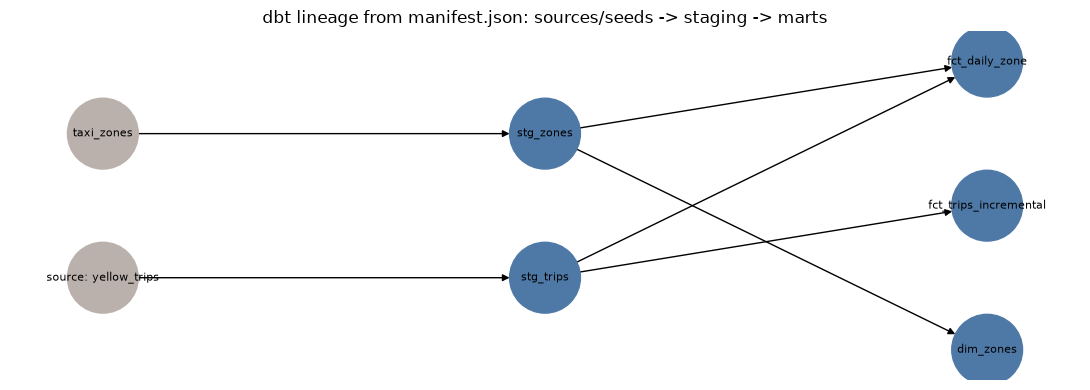

In [9]:
import networkx as nx

dbt("docs", "generate")
manifest = json.loads((PROJ / "target" / "manifest.json").read_text())
G = nx.DiGraph()
for uid, node in {**manifest["nodes"], **manifest["sources"]}.items():
    if node["resource_type"] in ("model", "seed", "source"):
        label = node["name"] if node["resource_type"] != "source" else f"source: {node['name']}"
        G.add_node(uid, label=label, kind=node["resource_type"])
        for dep in node.get("depends_on", {}).get("nodes", []):
            G.add_edge(dep, uid)
layers = {uid: (0 if G.nodes[uid]["kind"] in ("source", "seed") else 1 if ".stg_" in uid else 2) for uid in G.nodes}
nx.set_node_attributes(G, layers, "layer")
pos = nx.multipartite_layout(G, subset_key="layer")
fig, ax = plt.subplots(figsize=(11, 4))
colors = {"source": "#BAB0AC", "seed": "#BAB0AC", "model": "#4E79A7"}
nx.draw_networkx(G, pos, labels=nx.get_node_attributes(G, "label"), node_color=[colors[G.nodes[n]["kind"]] for n in G],
                 node_size=2600, font_size=8, font_color="black", arrows=True, ax=ax)
ax.set_title("dbt lineage from manifest.json: sources/seeds -> staging -> marts")
ax.axis("off")
plt.tight_layout()
plt.show()

| dbt command | Does |
| :--- | :--- |
| `dbt seed` | load CSV seeds |
| `dbt run` | build models |
| `dbt test` | run tests |
| `dbt build` | seed + run + test in DAG order |
| `dbt run --select model+` | a model and everything downstream |
| `dbt docs generate / serve` | documentation website and lineage |

In production, `dbt build` runs from an orchestrator (Lessons 05–08) or in CI on every pull request ("slim CI": only changed models and their children).

*Insight: dbt brings software engineering to SQL: one model per file, explicit dependencies with `ref()`, tests next to the models, generated documentation, and everything in Git. Treat a failing test as a question about the data or the rule, and declare the grain of every mart in a test.*

## Real-World Use Case or Analogy

A dbt project is like a **cookbook with cross-references and quality checks**: each recipe (model) says which other recipes it uses (`ref`), each comes with a taste test (tests), and the index (docs) shows how all dishes depend on the basic sauces (staging models).

dbt is used by thousands of companies; "analytics engineer" job descriptions almost always list dbt, SQL and a cloud warehouse.